# 02 — Sample Design

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



## What this notebook settles

Five decisions, each with the evidence above it and a cell for your reasoning below it. **Write the reasoning before you run the evidence cells**, then compare. Everything downstream (NB03 onward) reads the label from `v_target`, so once these are settled, run `python scripts/refresh_views.py` if you change `config.py`, and record the decision in `docs/decisions.md`.

| # | Decision | Where it lives |
|---|---|---|
| 1 | Performance window (24 months) | `config.PERFORMANCE_WINDOW_MONTHS`, `config.PERFORMANCE_SNAPSHOT` |
| 2 | Bad event and indeterminates | `config.BAD_STATUSES`, `config.DELINQUENT_STATUSES`, timing constants |
| 3 | Exclusions | `exclusion` column in `v_target` (credit-policy rows today) |
| 4 | Split and the censored monitor range | `config.TRAIN_VINTAGES` … `MONITOR_VINTAGES`, `EARLY_WINDOW_MONTHS` |
| 5 | Sampling | full data vs. oversampled bads, prior correction |

Lending Club gives one snapshot per loan, not a payment history, so the month a loan reached 90+ DPD is reconstructed from `last_pymnt_d` (first miss = last payment + 1 month, 90 DPD = first miss + 3). That reconstruction is the proxy-target caveat the pilot report must state against VantageScore's observed 90+ DPD definition.

In [3]:
# The definition currently in force (edit config.py, then scripts/refresh_views.py, to change it)
from scorelab import target
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

print("snapshot          ", config.PERFORMANCE_SNAPSHOT)
print("window (months)   ", config.PERFORMANCE_WINDOW_MONTHS)
print("bad statuses      ", config.BAD_STATUSES)
print("delinquent (open) ", config.DELINQUENT_STATUSES)
print("timing            last payment +%d = first miss; +%d = 60 DPD; +%d = 90 DPD" % (
    config.MONTHS_LAST_PAYMENT_TO_FIRST_MISS, config.MONTHS_FIRST_MISS_TO_60DPD, config.MONTHS_FIRST_MISS_TO_90DPD))
print("early indicator   60+ DPD within", config.EARLY_WINDOW_MONTHS, "months")
print("incumbent         ", config.INCUMBENT_SCORE_NAME, "=", config.INCUMBENT_SCORE_SQL)

cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
print("\nv_target columns:", cols)

snapshot           2019-03-01
window (months)    24
bad statuses       ('Charged Off', 'Default')
delinquent (open)  ('Late (31-120 days)', 'Late (16-30 days)', 'In Grace Period')
timing            last payment +1 = first miss; +2 = 60 DPD; +3 = 90 DPD
early indicator   60+ DPD within 12 months
incumbent          fico_mid = (fico_range_low + fico_range_high) / 2.0

v_target columns: ['id', 'issue_d', 'vintage_year', 'vintage_quarter', 'term_months', 'loan_status', 'months_to_last_payment', 'exclusion', 'observable', 'early_observable', 'bad', 'indeterminate', 'label', 'early_bad']


### Decision 1 — Performance window

Questions to answer in the cell below, before running the evidence: How much of the eventual charge-off is visible by month 24? Where do the vintage curves flatten? What does a shorter window buy (more observable vintages) and cost (early bads only, lower bad rate, less like a bureau score)? Which vintages does the 24-month window leave censored?

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

Keep **24 months**.

**The curves have not flattened by month 24.** 2016 reaches 11.87% at 24 months, 14.77% at 30 and 16.63% at 36; 2013 goes from 8.82% to 13.40% between months 24 and 36. So 24 months is a definition choice, comparable with a 24-month bureau bad definition, not the point where losses stop.

**Capture.** The 24-month window catches 64.9% of the charge-offs seen at the snapshot, for a bad rate of 11.10% (excluding indeterminates). A 30-month window would catch 80.4% and a 36-month window 90.4%.

**Cost of a longer window.** It removes observability where the out-of-time test needs it:

| Window | Observable loans in the modelling vintages | Lost |
|---|---:|---|
| 24 months | 1,216,645 | none |
| 30 months | 1,117,235 | 99,410, all of 2016Q4 |
| 36 months | 922,253 | 294,392, all of 2016Q2–Q4 |

**Shorter windows** would capture only 20.4% (12 months) or 44.0% (18 months) of charge-offs, with bad rates of 3.50% and 7.55%.

**Censoring.** At 24 months only 2017Q1 in the monitor range is labelled (92,372 loans); 2017Q2–2018Q4 are monitored with the 12-month indicator and PSI/CSI.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

horizon,6,12,18,24,30,36
vintage_year,,,,,,
2013,0.0039,0.0265,0.0583,0.0882,0.1143,0.1340
2014,0.0037,0.0288,0.0645,0.0981,0.1290,0.1518
2015,0.0042,0.0339,0.0753,0.1127,0.1429,0.1646
2016,0.0055,0.0399,0.0830,0.1187,0.1477,0.1663
2017,0.0061,0.0377,0.0773,0.1055,NaN,NaN
2018,0.0061,0.0370,NaN,NaN,NaN,NaN


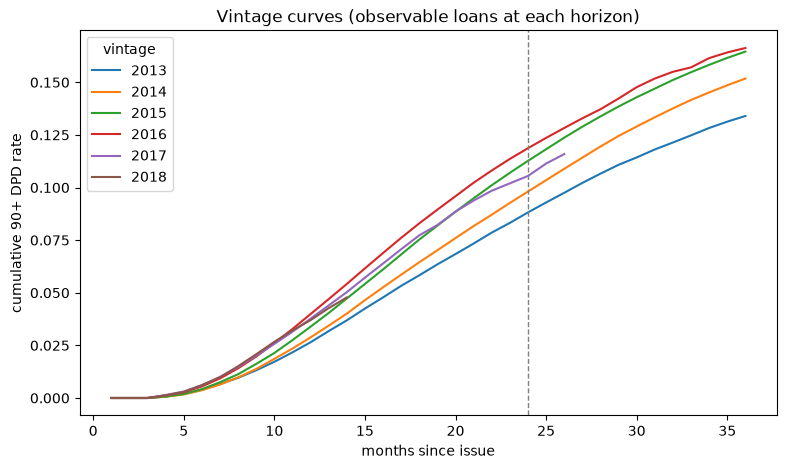

In [4]:
# Evidence 1a — vintage curves: cumulative share reaching 90+ DPD by month since issue
vc = target.vintage_curves(con, max_month=36)
table = vc[vc.horizon.isin([6, 12, 18, 24, 30, 36])].pivot(index="vintage_year", columns="horizon", values="cum_bad_rate")
display(table)

fig, ax = plt.subplots(figsize=(9, 5))
for vy, g in vc.groupby("vintage_year"):
    if vy >= min(config.TRAIN_VINTAGES):
        ax.plot(g.horizon, g.cum_bad_rate, label=str(vy))
ax.axvline(config.PERFORMANCE_WINDOW_MONTHS, color="grey", ls="--", lw=1)
ax.set_xlabel("months since issue"); ax.set_ylabel("cumulative 90+ DPD rate"); ax.set_title("Vintage curves (observable loans at each horizon)")
ax.legend(title="vintage"); plt.show()

In [5]:
# Evidence 1b — what alternative windows would do, on the modelling vintages
display(target.window_sensitivity(con, windows=(12, 18, 24, 30, 36)))

,window_months,n_observable,bad_rate_excl_indet,indeterminate_share,share_of_eventual_chargeoffs_captured
0,12,1216645.0,0.0350,0.0198,0.2036
1,18,1216645.0,0.0755,0.0186,0.4400
2,24,1216645.0,0.1110,0.0152,0.6493
3,30,1117235.0,0.1396,0.0119,0.8039
4,36,922253.0,0.1584,0.0081,0.9042


### Decision 2 — Bad event and indeterminates

The rule in force: bad = 90+ DPD reached inside the window (Charged Off / Default, or an open delinquency, timed from the last payment); indeterminate = first miss inside the window but 90+ only after it; good = everything else observable, including loans that defaulted after the window closed.

Questions: Is a loan that charged off in month 30 of a 60-month term "good" for a 24-month score? (Under VantageScore's definition, yes.) Is the indeterminate share small enough to exclude without bias, and what does the sensitivity in NB08 need to show? Should `Late (31-120 days)` at the snapshot ever count as bad for an observable loan?

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

Keep the rule in force.

- **Bad:** 90+ DPD inside 24 months (charged off or defaulted, or an open delinquency), timed from the last payment.
- **Good:** everything else observable, including loans that went bad after month 24. A charge-off in month 30 is good, as in a 24-month bureau definition.
- **Indeterminate:** boundary-timing cases. The first missed payment falls inside the window, but 90 DPD is reached just after it, in months 25–27. These are not mild delinquencies: almost all went on to charge off.

**Who the indeterminates are.** There are 18,469 in the modelling vintages (1.52% of observable loans). Almost all are charge-offs whose last payment came in months 21–23, so they reach 90 DPD in months 25–27:

| Status | Term | Loans |
|---|---|---:|
| Charged off | 36 months | 11,354 |
| Charged off | 60 months | 7,181 |
| Late (31–120 days) | any | 105 |
| Default | 36 months | 1 |

**Excluded from fitting.** NB08 will show the sensitivity to how indeterminates are treated. For 2016:

| Treatment | Bad rate |
|---|---:|
| Excluded (the rule in force) | 12.06% |
| Counted as good | 11.89% (50,591 / 425,618) |
| Counted as bad | 13.30% ((50,591 + 6,007) / 425,618) |

NB08 will also show the ranking metrics under each treatment.

**`Late (31-120 days)` at the snapshot.** It needs no special rule: the timing already decides it.

In [6]:
# Evidence 2a — label counts and rates by vintage, split and term
display(target.label_summary(con, by="vintage_year"))
display(target.label_summary(con, by="split"))
display(target.label_summary(con, by="term_months"))

,vintage_year,n_all,n_observable,n_bad,n_indeterminate,n_good,bad_rate_incl_indet,bad_rate_excl_indet,early_bad_rate_12m
0,2007,251,251.0,27.0,3.0,221.0,0.1076,0.1089,0.0239
1,2008,1562,1562.0,166.0,32.0,1364.0,0.1063,0.1085,0.0384
2,2009,4716,4716.0,408.0,43.0,4265.0,0.0865,0.0873,0.0420
3,2010,11536,11536.0,820.0,122.0,10594.0,0.0711,0.0718,0.0302
4,2011,21721,21721.0,1866.0,259.0,19596.0,0.0859,0.0869,0.0355
5,2012,53367,53367.0,5182.0,744.0,47441.0,0.0971,0.0985,0.0373
6,2013,134814,134814.0,11889.0,1884.0,121041.0,0.0882,0.0894,0.0318
7,2014,235629,235629.0,23116.0,3785.0,208728.0,0.0981,0.0997,0.0344
8,2015,420584,420584.0,47405.0,6793.0,366386.0,0.1127,0.1146,0.0404
9,2016,425618,425618.0,50591.0,6007.0,369020.0,0.1189,0.1206,0.0472


,split,n_all,n_observable,n_bad,n_indeterminate,n_good,bad_rate_incl_indet,bad_rate_excl_indet,early_bad_rate_12m
0,monitor,827411,92372.0,9803.0,1481.0,81088.0,0.1061,0.1079,0.0435
1,oot,425618,425618.0,50591.0,6007.0,369020.0,0.1189,0.1206,0.0472
2,train,370443,370443.0,35005.0,5669.0,329769.0,0.0945,0.0960,0.0334
3,validate,420584,420584.0,47405.0,6793.0,366386.0,0.1127,0.1146,0.0404
4,NaN,93153,93153.0,8469.0,1203.0,83481.0,0.0909,0.0921,0.0363


,term_months,n_all,n_observable,n_bad,n_indeterminate,n_good,bad_rate_incl_indet,bad_rate_excl_indet,early_bad_rate_12m
0,36,1537545,1006547.0,96873.0,13214.0,896460.0,0.0962,0.0975,0.0368
1,60,599664,395623.0,54400.0,7939.0,333284.0,0.1375,0.1403,0.0525


In [7]:
# Evidence 2b — who the indeterminates are
display(target.indeterminate_profile(con))

,loan_status,term_months,n,min_months_to_last_payment,max_months_to_last_payment
0,Charged Off,36,11354,21,23
1,Charged Off,60,7181,21,23
2,Late (31-120 days),36,69,23,23
3,Late (31-120 days),60,36,21,23
4,Default,36,1,22,22


### Decision 3 — Exclusions

Today only the pre-2010 "Does not meet the credit policy" rows are flagged. Candidates to consider: joint applications (`application_type`), 60-month loans (a different product, or a segment?), loans with a null `last_pymnt_d` that are not charged off, states or purposes with too few loans to level.

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

**Credit-policy rows.** Keep the exclusion. It removes 0 loans from the modelling vintages, because all 2,749 such loans were issued before 2012.

**Joint applications are excluded** (`config.EXCLUDED_APPLICATION_TYPES`, exclusion `joint_application`).
- The waterfall removes 9,300: none in train, 511 in validate and 8,789 in 2016. Another 111,410 are removed from the monitor range.
- The card would otherwise be tested on applicants it never saw, and the joint-application fields are out of scope for v1.
- Their bad rates are not unusual (10.36% and 12.12% in 2016), so the case for excluding them is the training population, not risk.

**60-month loans are kept** and reported as a segment.
- They are 107,451 of 370,443 train loans.
- They go bad at 12.47% in train against 8.43% for 36 months, and 15.17% against 11.01% in 2016.

**Not measured in this notebook:** loans with a null `last_pymnt_d` that are not charged off, and states or purposes too thin to level. Check both in NB03.

In [8]:
# Evidence 3 — exclusion flags and candidate exclusions by split
display(con.sql("""
    SELECT split, exclusion, COUNT(*) AS n FROM v_split GROUP BY 1, 2 ORDER BY 1, 2
""").df())
display(con.sql("""
    SELECT s.split, a.application_type, s.term_months, COUNT(*) AS n,
           ROUND(AVG(CASE WHEN s.label = 'bad' THEN 1 WHEN s.label = 'good' THEN 0 END), 4) AS bad_rate
    FROM v_split s JOIN v_accepted_asof a USING (id)
    WHERE s.observable = 1 AND s.split IN ('train', 'validate', 'oot')
    GROUP BY 1, 2, 3 ORDER BY 1, 2, 3
""").df())

,split,exclusion,n
0,monitor,joint_application,111410
1,monitor,NaN,827411
2,oot,joint_application,8789
3,oot,NaN,425618
4,train,NaN,370443
5,validate,joint_application,511
6,validate,NaN,420584
7,NaN,credit_policy,2749
8,NaN,NaN,93153


,split,application_type,term_months,n,bad_rate
0,oot,Individual,36,318277,0.1101
1,oot,Individual,60,107341,0.1517
2,oot,Joint App,36,5218,0.1036
3,oot,Joint App,60,3571,0.1212
4,train,Individual,36,262992,0.0843
5,train,Individual,60,107451,0.1247
6,validate,Individual,36,282934,0.0994
7,validate,Individual,60,137650,0.1459
8,validate,Joint App,36,239,0.1164
9,validate,Joint App,60,272,0.1381


In [9]:
# Evidence 3b — exclusion waterfall: from all accepted loans to the labelled modelling sample
display(target.exclusion_waterfall(con))

,train,validate,oot,total,removed,bads_remaining
all accepted loans,<NA>,<NA>,<NA>,2260668,<NA>,<NA>
issued in the modelling vintages,370443,421095,434407,1225945,1034723,<NA>
minus 'does not meet the credit policy' loans,370443,421095,434407,1225945,0,<NA>
minus joint applications,370443,420584,425618,1216645,9300,<NA>
minus loans whose 24-month window is not closed,370443,420584,425618,1216645,0,<NA>
minus indeterminates (labelled sample),364774,413791,419611,1198176,18469,133001


### Decision 4 — Split and the censored monitor range

Train 2013–2014, validate 2015, out-of-time 2016, monitor 2017Q1–2018Q4. At the 2019-03 snapshot only 2017Q1 is observable at 24 months; the rest of the monitor range carries the 12-month early indicator (60+ DPD) and the distribution metrics (PSI/CSI) instead. Is 2016 the right out-of-time year, given its bad rate is the highest in the data? Should validate be used for early stopping and calibration only, never for model selection against OOT?

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

**Splits:** train 2013–2014, validate 2015, out-of-time 2016, monitor 2017Q1–2018Q4.

**Bad rate rises over time:**

| Split | Bad rate |
|---|---:|
| Train (2013–2014) | 9.60% |
| Validate (2015) | 11.46% |
| Out-of-time (2016) | 12.06% |

By year it is 8.94% (2013) and 9.97% (2014). Within 2016 it ranges from 11.33% (Q4) to 12.61% (Q3).

**2016 is the right out-of-time year.** It is the latest fully observable year and the hardest. Expect the card to rank well but under-predict, so the pilot reports calibration separately from ranking.

Models are tuned and chosen on 2015. The 2016 out-of-time year is reported once, after those choices are fixed.

**Monitor.** 2017Q1 is labelled at 24 months (92,372 loans; 10.79% bad). The 12-month early indicator covers 492,687 monitor loans (4.35% early bad, against 4.72% for 2016).

In [10]:
# Evidence 4 — split sizes, observability and the early indicator by quarter
display(con.sql("""
    SELECT split, COUNT(*) AS n, SUM(observable) AS n_observable_24m, SUM(early_observable) AS n_observable_12m,
           ROUND(AVG(CASE WHEN label = 'bad' THEN 1 WHEN label = 'good' THEN 0 END), 4) AS bad_rate_24m,
           ROUND(AVG(early_bad), 4) AS early_bad_rate_12m
    FROM v_split WHERE exclusion IS NULL GROUP BY 1 ORDER BY 1
""").df())
display(target.label_summary(con, by="vintage_quarter").query("vintage_quarter >= '2016Q1'"))

,split,n,n_observable_24m,n_observable_12m,bad_rate_24m,early_bad_rate_12m
0,monitor,827411,92372.0,492687.0,0.1079,0.0435
1,oot,425618,425618.0,425618.0,0.1206,0.0472
2,train,370443,370443.0,370443.0,0.0960,0.0334
3,validate,420584,420584.0,420584.0,0.1146,0.0404
4,NaN,93153,93153.0,93153.0,0.0921,0.0363


,vintage_quarter,n_all,n_observable,n_bad,n_indeterminate,n_good,bad_rate_incl_indet,bad_rate_excl_indet,early_bad_rate_12m
35,2016Q1,131226,131226.0,15632.0,1823.0,113771.0,0.1191,0.1208,0.0462
36,2016Q2,96379,96379.0,11605.0,1294.0,83480.0,0.1204,0.1220,0.0479
37,2016Q3,98603,98603.0,12254.0,1459.0,84890.0,0.1243,0.1261,0.0492
38,2016Q4,99410,99410.0,11100.0,1431.0,86879.0,0.1117,0.1133,0.0459
39,2017Q1,92372,92372.0,9803.0,1481.0,81088.0,0.1061,0.1079,0.0422
40,2017Q2,98638,0.0,0.0,0.0,0.0,NaN,NaN,0.0448
41,2017Q3,108707,0.0,0.0,0.0,0.0,NaN,NaN,0.0452
42,2017Q4,101437,0.0,0.0,0.0,0.0,NaN,NaN,0.0428
43,2018Q1,91533,0.0,0.0,0.0,0.0,NaN,NaN,0.0422
44,2018Q2,112685,0.0,0.0,0.0,0.0,NaN,NaN,NaN


### Decision 5 — Sampling

With roughly 40k bads in train there is no need to oversample; the full data fits on an ordinary machine. If you do subsample goods for speed, the intercept must be corrected afterwards (`target.prior_correct_intercept`), or every odds-to-score table is off by the sampling ratio.

**Your reasoning:**

**DECIDED 2026-10-31** (drafted by Claude from this notebook's full-data outputs, applied; pending final review by Siavash)

**Use the full data, with no oversampling and therefore no prior correction.**

- **Bads are plentiful:** 35,005 in train, 47,405 in validate and 50,591 in out-of-time.
- **The full labelled modelling sample** is 1,198,176 loans.
- **Fitting notebooks** run with `SAMPLE_FRAC = None`.
- **The 10% exploration sample** (119,305 rows, 78 columns) is fine for quick passes. It reproduces each split's bad rate within 0.2 percentage points: train 9.55%, validate 11.63%, out-of-time 12.15%.

In [11]:
# Evidence 5 — bads per split and the size of the full modelling frame; prior-correction example
display(con.sql("""
    SELECT split, SUM(CASE WHEN label = 'bad' THEN 1 ELSE 0 END) AS bads,
           SUM(CASE WHEN label = 'good' THEN 1 ELSE 0 END) AS goods
    FROM v_split WHERE split IN ('train', 'validate', 'oot') AND exclusion IS NULL GROUP BY 1 ORDER BY 1
""").df())
import math
print("Fit on a 1:1 sample when the population bad rate is 10%  ->  intercept shift of",
      round(target.prior_correct_intercept(0.0, 0.5, 0.10), 3), "(= -ln 9)")
# A 10% exploration sample of the modelling frame:
frame = target.modeling_frame(con, sample_frac=0.10)
print(frame.shape); display(frame.groupby("split")["bad"].agg(["mean", "count"]))

,split,bads,goods
0,oot,50591.0,369020.0
1,train,35005.0,329769.0
2,validate,47405.0,366386.0


Fit on a 1:1 sample when the population bad rate is 10%  ->  intercept shift of -2.197 (= -ln 9)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(119305, 78)


,mean,count
split,,
oot,0.121517,41912
train,0.095471,36252
validate,0.116332,41141


## Record

Paste the decisions into `docs/decisions.md` (dated) and the definition into `docs/model_card.md`. The cell below prints a draft with the numbers filled in; edit the wording, not the numbers.

In [12]:
s = target.label_summary(con, by="split").set_index("split")
ws = target.window_sensitivity(con, windows=(config.PERFORMANCE_WINDOW_MONTHS,)).iloc[0]
print(f"""## {pd.Timestamp.today():%Y-%m-%d} — Target definition and sample design (NB02)

- Performance observed at the {config.PERFORMANCE_SNAPSHOT} snapshot; window {config.PERFORMANCE_WINDOW_MONTHS} months.
- Bad = 90+ DPD inside the window, reconstructed from last_pymnt_d (+{config.MONTHS_LAST_PAYMENT_TO_FIRST_MISS} first miss,
  +{config.MONTHS_FIRST_MISS_TO_90DPD} to 90 DPD); statuses {config.BAD_STATUSES} and open delinquencies {config.DELINQUENT_STATUSES}.
- Indeterminate = first miss inside the window, 90+ after it: excluded from fitting, reported in NB08 sensitivity.
- Loans delinquent only after the window are good (vendor-style definition). Charge-offs captured by the window:
  {ws.share_of_eventual_chargeoffs_captured:.1%} of those observed at the snapshot.
- Bad rate excluding indeterminates: train {s.loc['train','bad_rate_excl_indet']:.2%}, validate {s.loc['validate','bad_rate_excl_indet']:.2%},
  oot {s.loc['oot','bad_rate_excl_indet']:.2%}; indeterminate share about {ws.indeterminate_share:.1%}.
- Split: train {config.TRAIN_VINTAGES}, validate {config.VALIDATE_VINTAGE}, oot {config.OOT_VINTAGE}, monitor {config.MONITOR_VINTAGES}
  (censored at 24 months; monitored with 60+ DPD within {config.EARLY_WINDOW_MONTHS} months and PSI/CSI).
- Incumbent score for the pilot: {config.INCUMBENT_SCORE_NAME} = {config.INCUMBENT_SCORE_SQL}.
- Exclusions: credit-policy rows; <add yours>.
- Sampling: <full data / sample + prior correction>.
""")

## 2026-10-31 — Target definition and sample design (NB02)

- Performance observed at the 2019-03-01 snapshot; window 24 months.
- Bad = 90+ DPD inside the window, reconstructed from last_pymnt_d (+1 first miss,
  +3 to 90 DPD); statuses ('Charged Off', 'Default') and open delinquencies ('Late (31-120 days)', 'Late (16-30 days)', 'In Grace Period').
- Indeterminate = first miss inside the window, 90+ after it: excluded from fitting, reported in NB08 sensitivity.
- Loans delinquent only after the window are good (vendor-style definition). Charge-offs captured by the window:
  64.9% of those observed at the snapshot.
- Bad rate excluding indeterminates: train 9.60%, validate 11.46%,
  oot 12.06%; indeterminate share about 1.5%.
- Split: train (2013, 2014), validate 2015, oot 2016, monitor ('2017Q1', '2018Q4')
  (censored at 24 months; monitored with 60+ DPD within 12 months and PSI/CSI).
- Incumbent score for the pilot: fico_mid = (fico_range_low + fico_range_high) / 2.0.
- Exclusions: c